# Izhikevich neuron runner

In [1]:

import numpy as np
import torch
from pymonntorch import *
from matplotlib import pyplot as plt
from network import TimeResolution
from neuron import Izhikevich
from current import ScheduledCurrent
from parameters import PATTERNS, DT



In [2]:
def run_pattern(p, dt=DT):
    
    net = Network(behavior={1: TimeResolution(dt=dt)})
    ng = NeuronGroup(
        net=net, size=1,
        behavior={
            10: ScheduledCurrent(schedule=p["schedule"]),
            20: Izhikevich(a=p["a"], b=p["b"], c=p["c"], d=p["d"], v_init=p["v_init"]),
            600:Recorder(["v", "u", "I"]),
            601: EventRecorder(["spikes"]),
        },
        tag="ng",
    )
    net.initialize()
    net.simulate_iterations(int(p["T"] / dt))

    v_raw = torch.as_tensor(ng["v", 0])
    v =v_raw[:, 0].cpu().numpy()
    u= torch.as_tensor(ng["u", 0])[:, 0].cpu().numpy()
    I =torch.as_tensor(ng["I", 0])[:, 0].cpu().numpy()
    t =np.arange(len(v)) * dt
    return t, v, u, I

THRESHOLD = 30  

def plot_pattern(name, p, clip=True):
    t, v, u, I = run_pattern(p)
    if clip:
        v = np.minimum(v, THRESHOLD)
    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(7, 6), sharex=True,
                                        gridspec_kw={"height_ratios": [3, 2, 1]})
    ax1.plot(t, v, "k", lw=0.8)
    ax1.axhline(THRESHOLD, color="gray", ls="--", lw=0.8, label=f"spike cutoff ({THRESHOLD} mV)")
    ax1.axhline(p["c"], color="orange", ls=":", lw=0.8, label=f"reset c ({p['c']} mV)")
    ax1.legend(fontsize=7, loc="upper right")
    ax1.set_ylabel("v (mV)")
    ax1.set_title(f"{name}: {p['name']}\na={p['a']}, b={p['b']}, c={p['c']}, d={p['d']}")
   
    ax2.plot(t, u, "r", lw=0.8)
    ax2.set_ylabel("u (recovery)")
   
    ax3.plot(t, I, "b")
    ax3.set_ylabel("I"); ax3.set_xlabel("time (ms)")
   
    fig.tight_layout()
    plt.show()
    return t, v, u, I

In [ ]:

run_pattern(PATTERNS["RZ"])
_ = plot_pattern("RZ", PATTERNS["RZ"])

In [ ]:
for name, p in PATTERNS.items():
    plot_pattern(name, p)
    

## Parameter table

In [ ]:
print("| Pattern | a | b | c | d | v_init | I schedule |")
print("|---|---|---|---|---|---|---|")
for name, p in PATTERNS.items():
    print(f"| {name} ({p['name']}) | {p['a']} | {p['b']} | {p['c']} | {p['d']} | {p['v_init']} | {p['schedule']} |")

## Low , Medium , High I input for RS pattern 

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 5)],)20:Izhikevich(a=0.025,b=0.2,c=-65,d=8,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
3000xBatch: 1/1 (100%) 758.179ms
Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.025,b=0.2,c=-65,d=8,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
3000xBatch: 1/1 (100%) 865.6

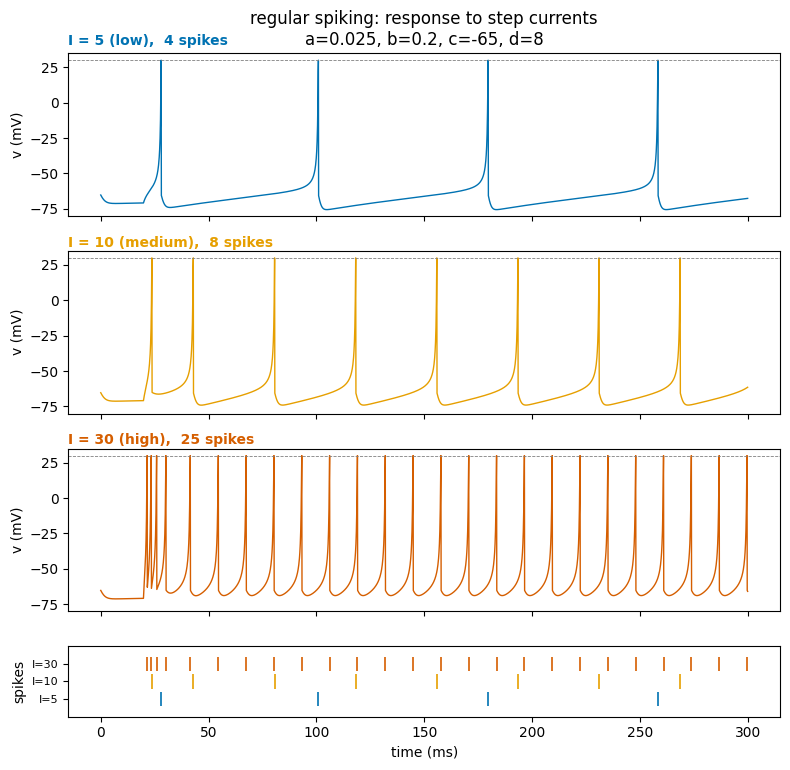

In [3]:
from plot_step_compare import plot_step_stacked
from parameters import STEP_PATTERNS


plot_step_stacked(STEP_PATTERNS, run_pattern)

Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 4)],)20:Izhikevich(a=0.025,b=0.2,c=-65,d=8,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
3000xBatch: 1/1 (100%) 917.330ms
Network['Network_1', 'Network'](Neurons: tensor(1)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](1){10:ScheduledCurrent(schedule=[(0, 0), (20, 10)],)20:Izhikevich(a=0.025,b=0.2,c=-65,d=8,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)601:EventRecorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['spikes'],)}
3000xBatch: 1/1 (100%) 938.2

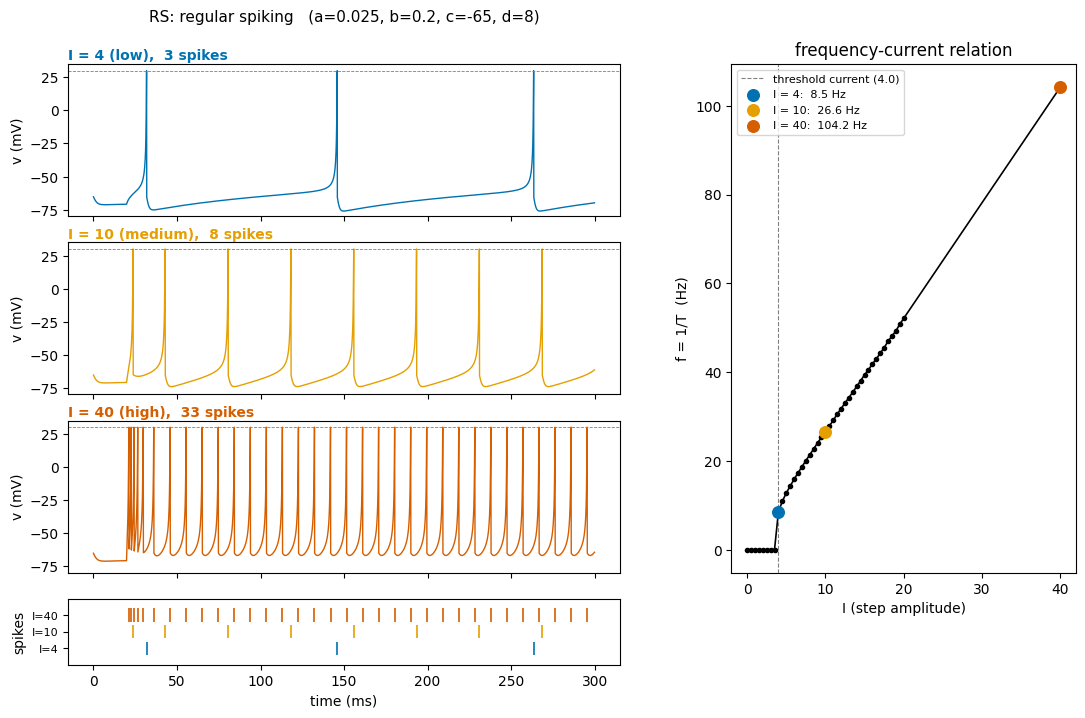

(array([ 0. ,  0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,
         5.5,  6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. , 10.5,
        11. , 11.5, 12. , 12.5, 13. , 13.5, 14. , 14.5, 15. , 15.5, 16. ,
        16.5, 17. , 17.5, 18. , 18.5, 19. , 19.5, 20. , 40. ]),
 array([  0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          8.50195545,  10.90274749,  12.71294177,  14.31844215,
         15.82779361,  17.25923369,  18.65671642,  20.01601281,
         21.34927412,  22.66545784,  24.03846154,  25.29084471,
         26.5674814 ,  27.82415136,  29.12055911,  30.48780488,
         31.74603175,  33.00330033,  34.24657534,  35.46099291,
         36.76470588,  38.02281369,  39.37007874,  40.48582996,
         41.84100418,  42.91845494,  44.24778761,  45.45454545,
         46.94835681,  48.07692308,  49.26108374,  50.76142132,
         52.08333333, 104.16666667]))

In [3]:
from plot_step_compare import plot_step_and_FI
from parameters import PATTERNS, STEP_PATTERNS

plot_step_and_FI(STEP_PATTERNS, run_pattern, PATTERNS["RS"], name="RS")

Network['Network_1', 'Network'](Neurons: tensor(41)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](41){10:StepSweepCurrent(I_values=[np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0), np.float64(5.5), np.float64(6.0), np.float64(6.5), np.float64(7.0), np.float64(7.5), np.float64(8.0), np.float64(8.5), np.float64(9.0), np.float64(9.5), np.float64(10.0), np.float64(10.5), np.float64(11.0), np.float64(11.5), np.float64(12.0), np.float64(12.5), np.float64(13.0), np.float64(13.5), np.float64(14.0), np.float64(14.5), np.float64(15.0), np.float64(15.5), np.float64(16.0), np.float64(16.5), np.float64(17.0), np.float64(17.5), np.float64(18.0), np.float64(18.5), np.float64(19.0), np.float64(19.5), np.float64(20.0)],t_start=100,)20:Izhikevich(a=0.0225,b=0.2,c=-55,d=4,v_init=-65,)600:Recorder(variables=None,gap

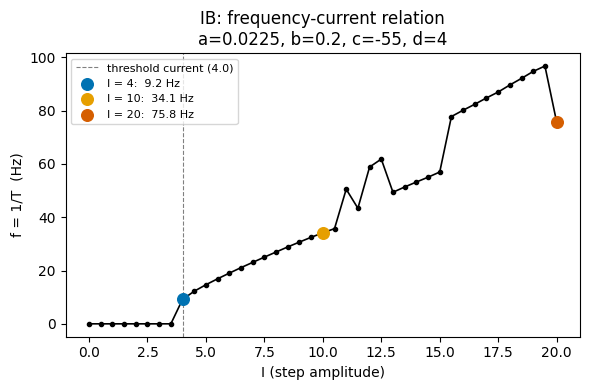

Network['Network_1', 'Network'](Neurons: tensor(41)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](41){10:StepSweepCurrent(I_values=[np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0), np.float64(5.5), np.float64(6.0), np.float64(6.5), np.float64(7.0), np.float64(7.5), np.float64(8.0), np.float64(8.5), np.float64(9.0), np.float64(9.5), np.float64(10.0), np.float64(10.5), np.float64(11.0), np.float64(11.5), np.float64(12.0), np.float64(12.5), np.float64(13.0), np.float64(13.5), np.float64(14.0), np.float64(14.5), np.float64(15.0), np.float64(15.5), np.float64(16.0), np.float64(16.5), np.float64(17.0), np.float64(17.5), np.float64(18.0), np.float64(18.5), np.float64(19.0), np.float64(19.5), np.float64(20.0)],t_start=100,)20:Izhikevich(a=0.02,b=0.2,c=-50,d=2,v_init=-65,)600:Recorder(variables=None,gap_w

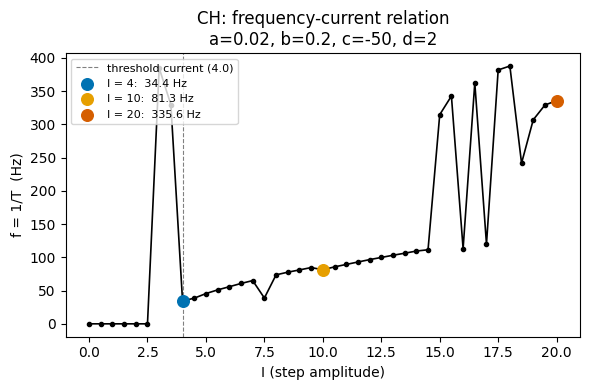

Network['Network_1', 'Network'](Neurons: tensor(41)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](41){10:StepSweepCurrent(I_values=[np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0), np.float64(5.5), np.float64(6.0), np.float64(6.5), np.float64(7.0), np.float64(7.5), np.float64(8.0), np.float64(8.5), np.float64(9.0), np.float64(9.5), np.float64(10.0), np.float64(10.5), np.float64(11.0), np.float64(11.5), np.float64(12.0), np.float64(12.5), np.float64(13.0), np.float64(13.5), np.float64(14.0), np.float64(14.5), np.float64(15.0), np.float64(15.5), np.float64(16.0), np.float64(16.5), np.float64(17.0), np.float64(17.5), np.float64(18.0), np.float64(18.5), np.float64(19.0), np.float64(19.5), np.float64(20.0)],t_start=100,)20:Izhikevich(a=0.1,b=0.2,c=-65,d=2,v_init=-65,)600:Recorder(variables=None,gap_wi

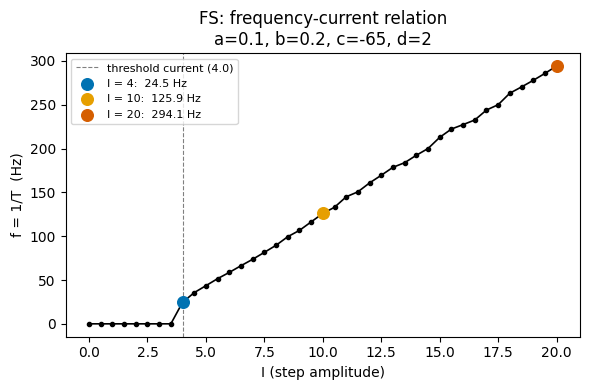

Network['Network_1', 'Network'](Neurons: tensor(31)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](31){10:StepSweepCurrent(I_values=[np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0), np.float64(5.5), np.float64(6.0), np.float64(6.5), np.float64(7.0), np.float64(7.5), np.float64(8.0), np.float64(8.5), np.float64(9.0), np.float64(9.5), np.float64(10.0), np.float64(10.5), np.float64(11.0), np.float64(11.5), np.float64(12.0), np.float64(12.5), np.float64(13.0), np.float64(13.5), np.float64(14.0), np.float64(14.5), np.float64(15.0)],t_start=100,)20:Izhikevich(a=0.02,b=0.25,c=-65,d=2,v_init=-65,)600:Recorder(variables=None,gap_width=0,max_length=None,auto_annotate=True,tag=None,arg_0=['v', 'u', 'I'],)}
10000xBatch: 1/1 (100%) 4089.785ms


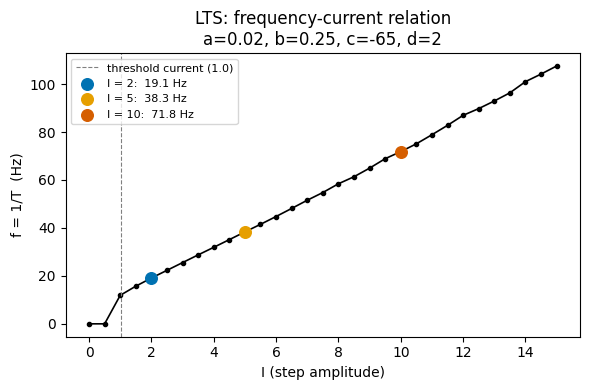

Network['Network_1', 'Network'](Neurons: tensor(42)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](42){10:StepSweepCurrent(I_values=[np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(0.75), np.float64(0.8), np.float64(1.0), np.float64(1.25), np.float64(1.5), np.float64(1.75), np.float64(2.0), np.float64(2.25), np.float64(2.5), np.float64(2.75), np.float64(3.0), np.float64(3.25), np.float64(3.5), np.float64(3.75), np.float64(4.0), np.float64(4.25), np.float64(4.5), np.float64(4.75), np.float64(5.0), np.float64(5.25), np.float64(5.5), np.float64(5.75), np.float64(6.0), np.float64(6.25), np.float64(6.5), np.float64(6.75), np.float64(7.0), np.float64(7.25), np.float64(7.5), np.float64(7.75), np.float64(8.0), np.float64(8.25), np.float64(8.5), np.float64(8.75), np.float64(9.0), np.float64(9.25), np.float64(9.5), np.float64(9.75), np.float64(10.0)],t_start=100,)20:Izhikevich(a=0.02,b=0.25,c=-65,d=0.05,v_init=-64.41,)600:Recor

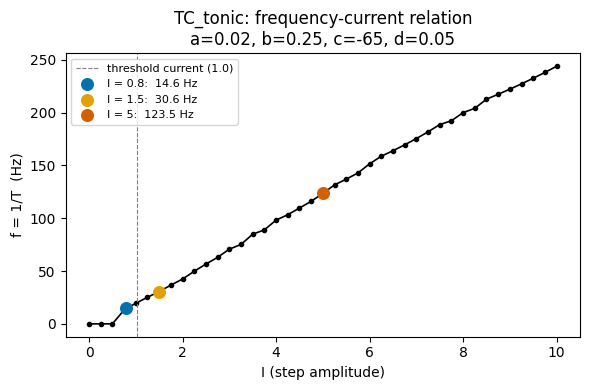

Network['Network_1', 'Network'](Neurons: tensor(42)|1 groups, Synapses: tensor(0.)|0 groups){1:TimeResolution(dt=0.1,)}
NeuronGroup['ng', 'NeuronGroup'](42){10:StepSweepCurrent(I_values=[np.float64(0.0), np.float64(0.2), np.float64(0.25), np.float64(0.5), np.float64(0.75), np.float64(1.0), np.float64(1.25), np.float64(1.5), np.float64(1.75), np.float64(2.0), np.float64(2.25), np.float64(2.5), np.float64(2.75), np.float64(3.0), np.float64(3.25), np.float64(3.5), np.float64(3.75), np.float64(4.0), np.float64(4.25), np.float64(4.5), np.float64(4.75), np.float64(5.0), np.float64(5.25), np.float64(5.5), np.float64(5.75), np.float64(6.0), np.float64(6.25), np.float64(6.5), np.float64(6.75), np.float64(7.0), np.float64(7.25), np.float64(7.5), np.float64(7.75), np.float64(8.0), np.float64(8.25), np.float64(8.5), np.float64(8.75), np.float64(9.0), np.float64(9.25), np.float64(9.5), np.float64(9.75), np.float64(10.0)],t_start=100,)20:Izhikevich(a=0.1,b=0.26,c=-65,d=2,v_init=-65,)600:Recorder(var

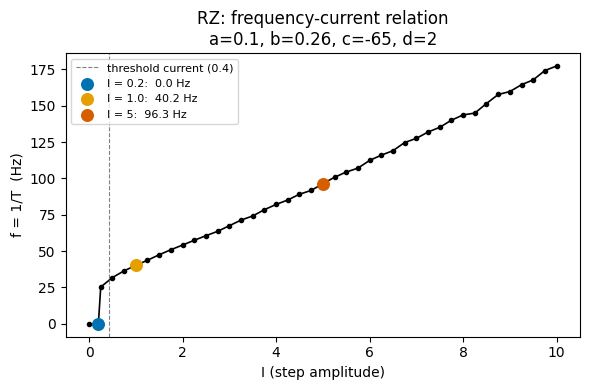

In [ ]:
import numpy as np
from step_current import plot_FI
from parameters import PATTERNS

FI_CONFIG = {
    "IB":  dict(currents=np.arange(0, 20.01, 0.5), mark=(4, 10, 20)),
    "CH": dict(currents=np.arange(0, 20.01, 0.5), mark=(4, 10, 20)),
    "FS":dict(currents=np.arange(0, 20.01, 0.5), mark=(4, 10, 20)),
    "LTS": dict(currents=np.arange(0, 15.01, 0.5), mark=(2, 5, 10)),
    "TC_tonic": dict(currents=np.arange(0, 10.01, 0.25), mark=(0.8, 1.5, 5)),
    "RZ": dict(currents=np.arange(0, 10.01, 0.25), mark=(0.2, 1.0, 5)),
}

for name, cfg in FI_CONFIG.items():
    plot_FI(
        name=name,
        p=PATTERNS[name],
        currents=cfg["currents"],
        T=1000,
        t_on=100,
        mark=cfg["mark"],
    )